# MESA Massive Star Diagnostics

In [1]:
import mesa_reader as mr

In [2]:
import pynucastro as pyna
from pynucastro import mesa_utils

We store zipped files to save space.  Unzip if they are not already

In [3]:
import os
import subprocess
files = ["LOGS/history.data", "LOGS_to_cc/history.data", "LOGS_to_cc/profile49.data"]
for f in files:
    if not os.path.isfile(f):
        subprocess.run(["gunzip", "-k", f"{f}.gz"], check=True)

This was run in two stages, so the history is split across two files.  Read both
and then concatenate.  This relies of the columns being the same (we check) and the
model numbers not resetting between stages.

In [4]:
h1 = mr.MesaData("LOGS/history.data")
h2 = mr.MesaData("LOGS_to_cc/history.data")

In [5]:
if h1.bulk_names != h2.bulk_names:
    raise ValueError("History columns differ between stages")

In [6]:
import copy
import numpy as np

In [7]:
history = copy.deepcopy(h1)
history.bulk_data = np.concatenate([h1.bulk_data, h2.bulk_data])
history.remove_backups()

## HR diagram

In [8]:
import matplotlib.pyplot as plt

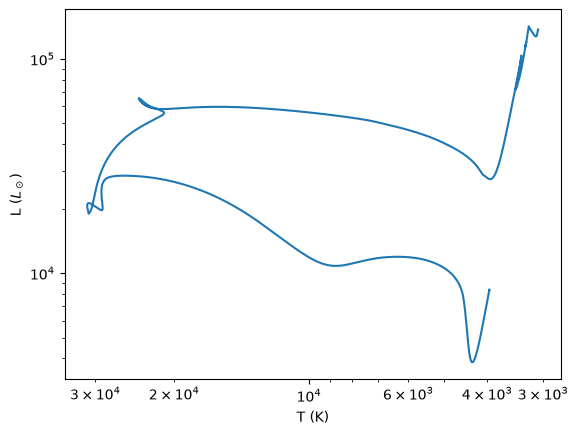

In [9]:
fig, ax = plt.subplots()
ax.loglog(history.Teff, history.L)
ax.set_xlabel("T (K)")
ax.set_ylabel(r"L ($L_\odot$)")
ax.invert_xaxis()

## Central evolution

We have a helper module that will give us the boundaries of the different equations of state.

In [10]:
import regimes

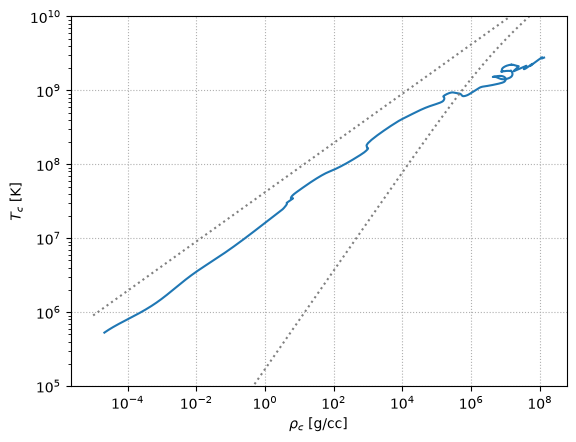

In [11]:
fig, ax = plt.subplots()

ax.loglog(history.center_Rho, history.center_T)

rho = np.logspace(-5, 8, 100)
ax.loglog(rho, regimes.deg_ideal(rho, mu_e=1.3), color="0.5", ls=":")
ax.loglog(rho, regimes.rad_ideal(rho, mu=0.6), color="0.5", ls=":")

ax.set_xlabel(r"$\rho_c$ [g/cc]")
ax.set_ylabel(r"$T_c$ [K]")

ax.set_ylim(1.e5, 1.e10)
ax.grid(ls=":")

## Temporal evolution

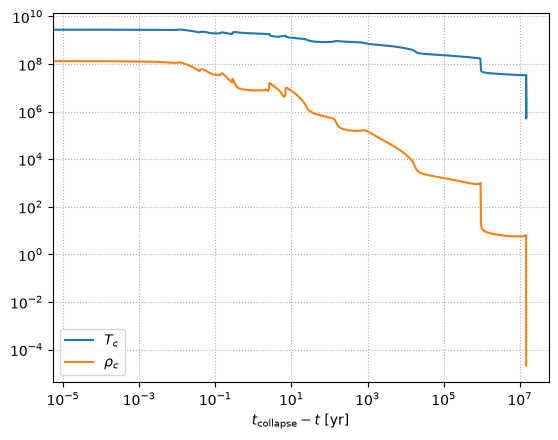

In [12]:
fig, ax = plt.subplots()

t_max = history.star_age.max()
ax.loglog(t_max-history.star_age, history.center_T, label=r"$T_c$")
ax.loglog(t_max-history.star_age, history.center_Rho, label=r"$\rho_c$")
ax.set_xlabel(r"$t_\mathrm{collapse} - t$ [yr]")

ax.grid(ls=":")
ax.legend()

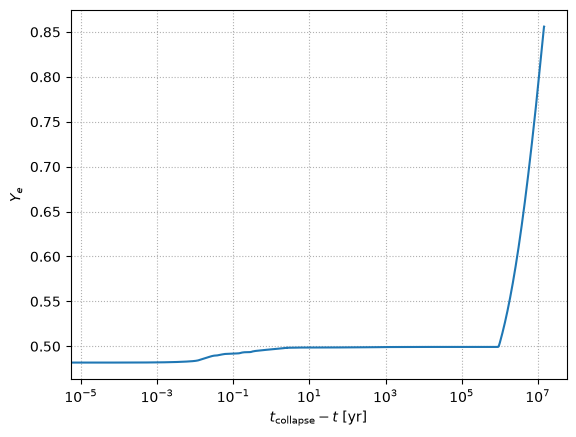

In [13]:
fig, ax = plt.subplots()
t_max = history.star_age.max()
ax.semilogx(t_max-history.star_age, history.center_ye)
ax.set_xlabel(r"$t_\mathrm{collapse} - t$ [yr]")
ax.set_ylabel(r"$Y_e$")
ax.grid(ls=":")

## Examining a profile

In [14]:
model = mr.MesaData("LOGS_to_cc/profile49.data")

In [15]:
mm = mesa_utils.MesaModel(model)

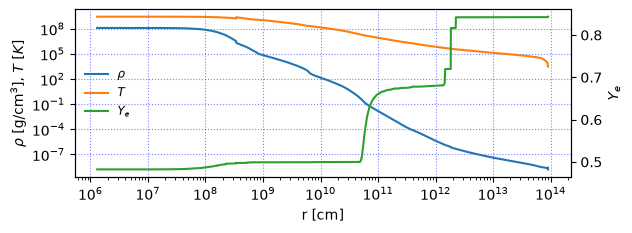

In [16]:
fig = plt.figure()
ax = fig.add_subplot(211)

r = mm.get_data_array("r")
rho = mm.get_data_array("rho")
T = mm.get_data_array("T")

l1 = ax.plot(r, rho, label=r"$\rho$")
l2 = ax.plot(r, T, label=r"$T$")

ax.set_xscale("log")
ax.set_yscale("log")

ax.set_xlabel("r [cm]")
ax.set_ylabel(r"$\rho~[\rm{g/cm^3}]$, $T~[K]$")

ax.grid(color="b", alpha=0.5, ls=":") 

ax2 = ax.twinx()

ax2.set_ylabel(r"$Y_e$") 
l3 = ax2.plot(r, model.ye, color="C2", label="$Y_e$")

lns = l1 + l2 + l3
labs = [l.get_label() for l in lns]
ax.legend(lns, labs, frameon=False, loc=6, fontsize="small")

In [17]:
ax = fig.add_subplot(212)
threshold = 0.05

for nuc in mesa_utils.get_nuclei(model):
    X = np.array([state.comp.X[nuc] for state in mm])
    Xmax = X.max()

    if Xmax > threshold:
        if Xmax > 0.5:
            lw = 3
            ls = "-"
        else:
            lw = 1.5
            ls = "--"
        ax.plot(r, X, label=f"{nuc!s}", lw=lw, ls=ls)

ax.set_xscale("log")
ax.set_yscale("log")

ax.set_xlabel("r [cm]")
ax.set_ylabel("mass fraction")

ax.set_ylim(1.e-6, 1.1)

ax.grid(color="b", alpha=0.5, ls=":") 
ax.legend(frameon=True, edgecolor="w", ncol=1, framealpha=0.5, fontsize="small") 

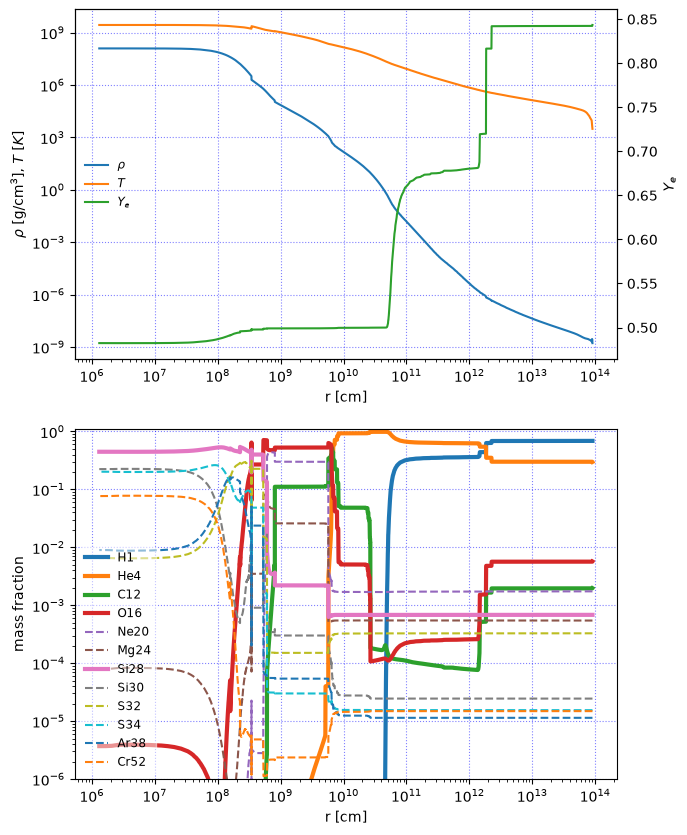

In [18]:
fig.set_size_inches(7, 10)
fig

In [19]:
fig.savefig("stellar_profile.png")

## Nuclear flow

In [20]:
nuc = mesa_utils.get_nuclei(model)

In [21]:
len(nuc)

128

In [22]:
net = pyna.network_helper(nuc, tabular_ordering=["ffn", "oda", "langanke"])

We'll look at the last zone (that's the center)

In [23]:
idx = mm.num_zones-1

In [24]:
state = mm.get_zone_data(idx)

<>:8: SyntaxWarning: "\o" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\o"? A raw string is also an option.
<>:8: SyntaxWarning: "\o" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\o"? A raw string is also an option.
/tmp/ipykernel_851273/546916320.py:8: SyntaxWarning: "\o" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\o"? A raw string is also an option.
  fig.suptitle(f"{model.initial_mass} $M_\odot$ MESA model", fontsize=24)
/home/zingale/development/pynucastro/pynucastro/rates/derived_rate.py:129: UserWarning: d partition function is not supported by tables: set log_pf = 0.0 by default
  warnings.warn(UserWarning(f'{nuc} partition function is not supported by tables: set log_pf = 0.0 by default'))
/home/zingale/development/pynucastro/pynucastro/rates/derived_rate.py:129: UserWarning: He3 partition function is not supported by tables: set log_pf = 0.0 

Text(0.85, 0.95, 't = $1.45835 \\times 10^{7}$ yr')

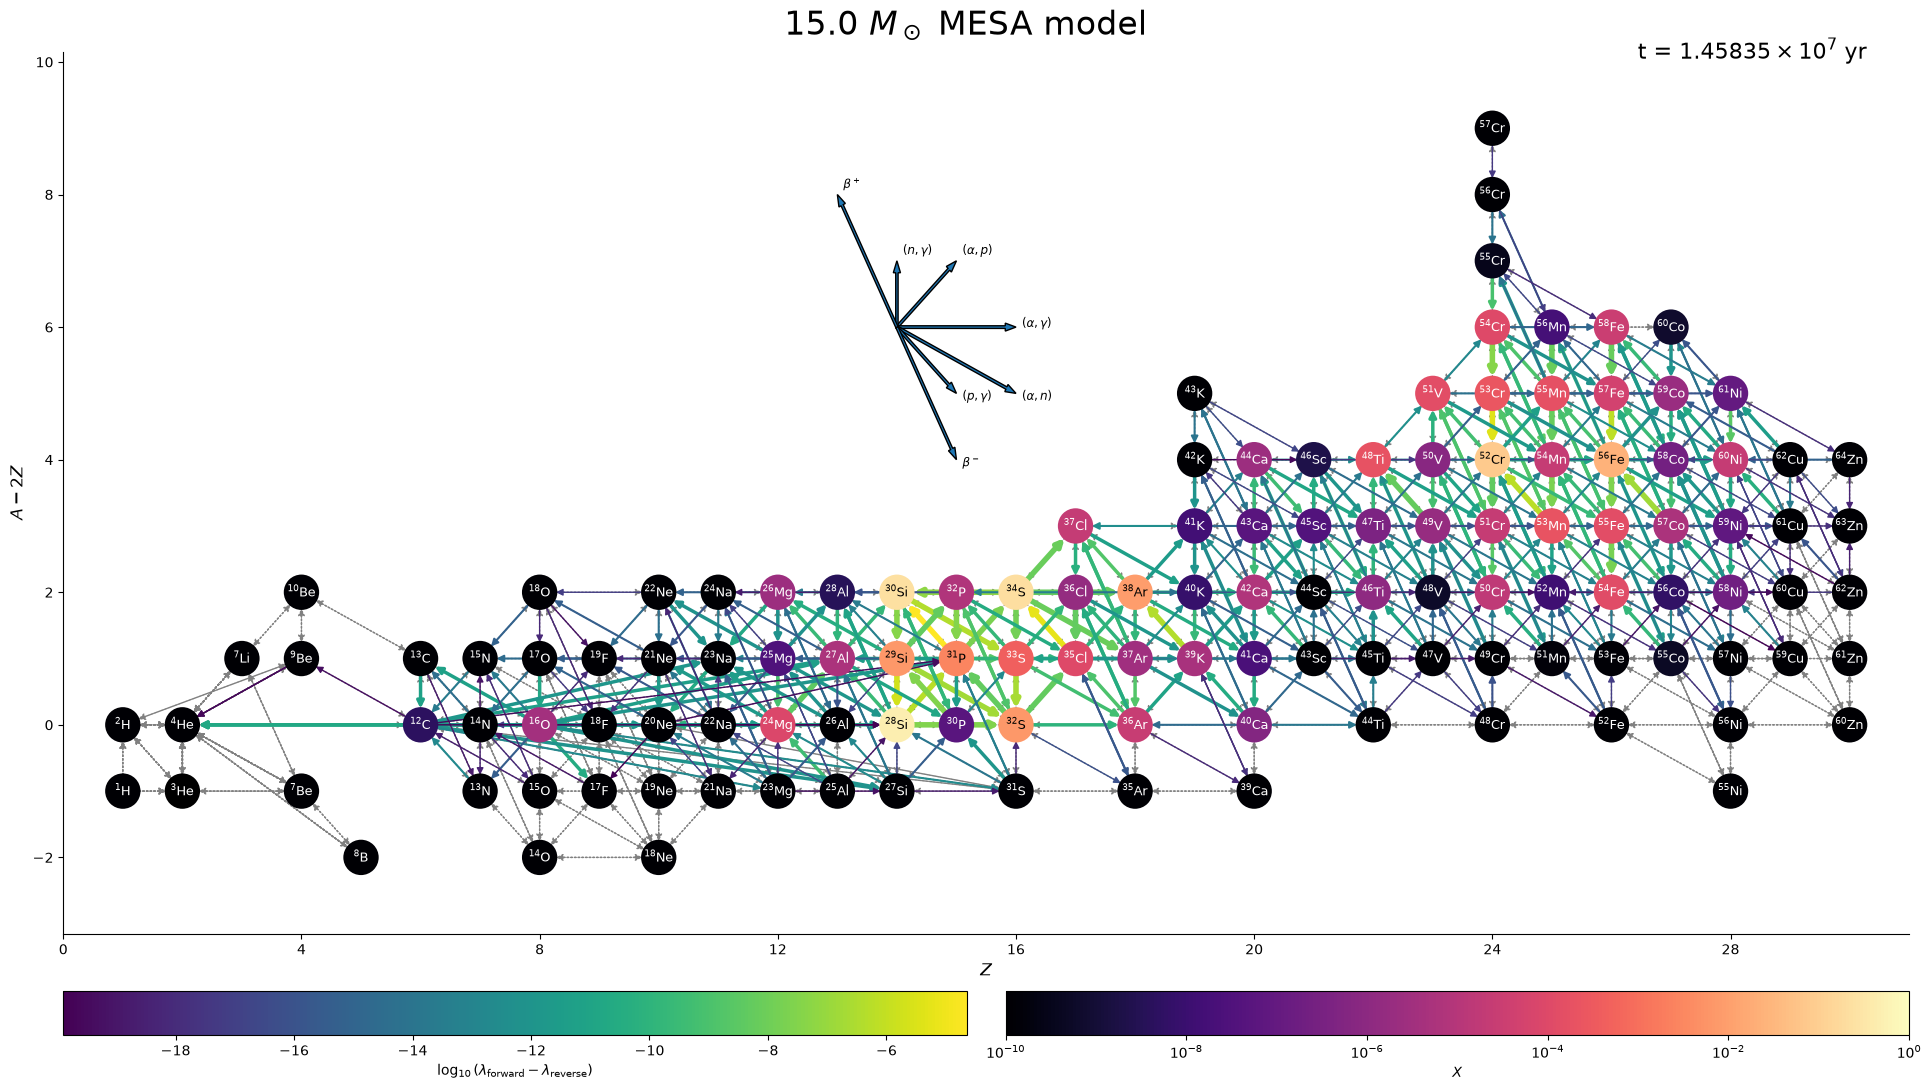

In [25]:
fig = net.plot(state.rho, state.T, state.comp,
               screen_func=pyna.screening.chugunov_2007,
               rotated=True,
               use_net_rate=True, color_nodes_by_abundance=True,
               size=(1920,1080), node_size=550, node_font_size=9,
               ydot_cutoff_value=1.e-20, show_small_ydot=True,
               legend_coord=(14,6), Z_range=[0, 31])
fig.suptitle(f"{model.initial_mass} $M_\odot$ MESA model", fontsize=24)
mantissa, exponent = f"{model.star_age:.5e}".split("e")
s = rf"${mantissa} \times 10^{{{int(exponent)}}}$"
fig.text(0.85, 0.95, f"t = {s} yr", fontsize=16)

In [26]:
fig.savefig("si_core.png")

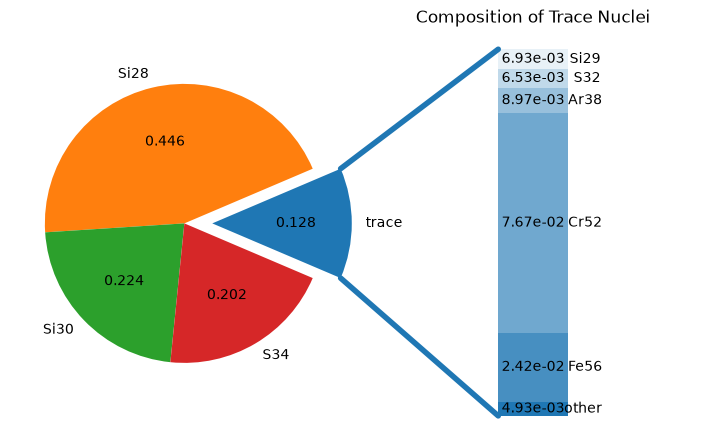

In [27]:
fig2 = state.comp.plot()

## Adding inset

In [28]:
ax_inset = fig.add_axes([0.1, 0.575, 0.275, 0.375])

ax_inset.loglog(history.center_Rho, history.center_T)

rho = np.logspace(-5, 8, 100)
ax_inset.loglog(rho, regimes.deg_ideal(rho, mu_e=1.3), color="0.5", ls=":")
ax_inset.loglog(rho, regimes.rad_ideal(rho, mu=0.6), color="0.5", ls=":")

# we are already looking at the very center of the star
ax_inset.scatter(state.rho, state.T, marker="*", color="C1")
ax_inset.set_xlabel(r"$\rho_c$ [g/cc]")
ax_inset.set_ylabel(r"$T_c$ [K]")

ax_inset.set_ylim(1.e5, 1.e10)
ax_inset.grid(ls=":")

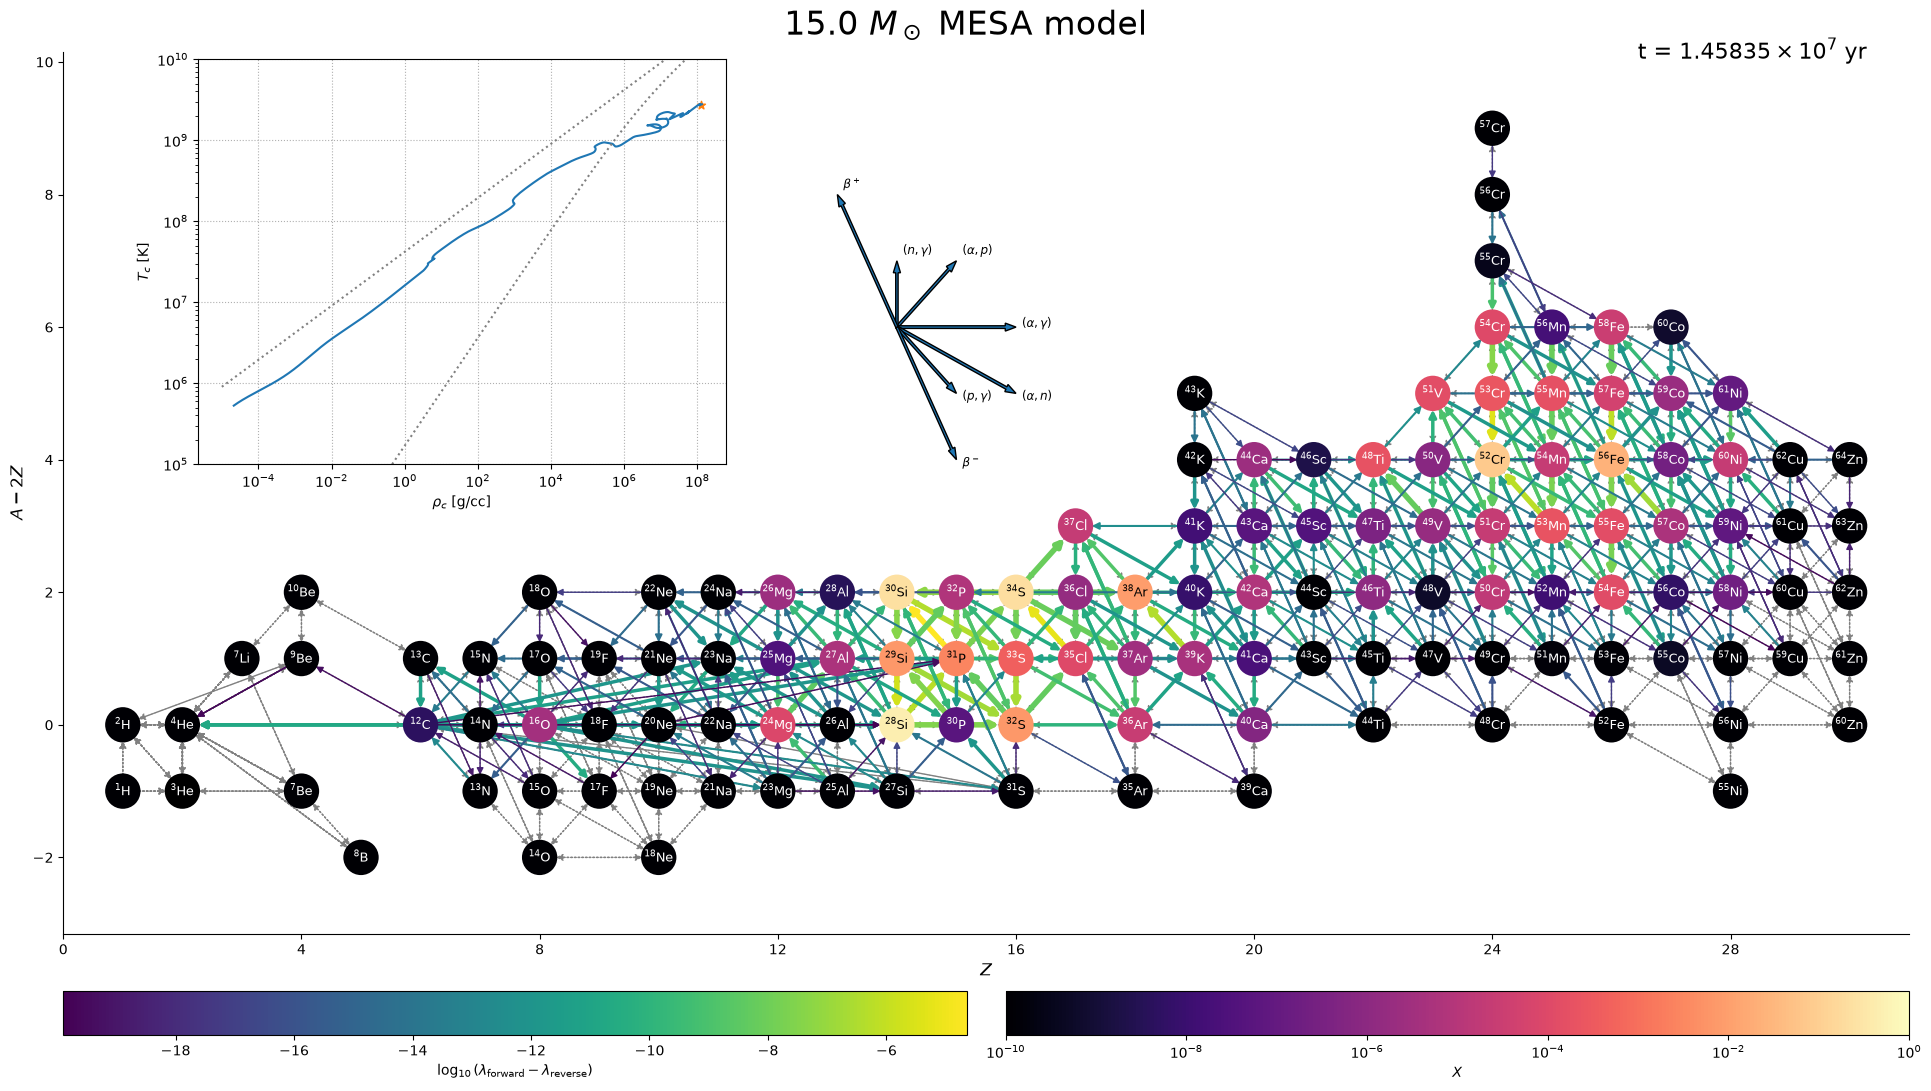

In [29]:
fig

In [30]:
fig.savefig("massive_star_net_vis.png")